# Notebook 01: Data Pipeline & Visualization (CelebA, Fashion-MNIST, CIFAR-10)
**Phân công nhiệm vụ 3.1 - Lâm**

Notebook này phục vụ việc:
1. Mount Google Drive hoặc kết nối Kaggle Dataset.
2. Kiểm tra và tiền xử lý 3 bộ dữ liệu: CelebA, Fashion-MNIST, CIFAR-10.
3. Khởi tạo và kiểm tra Train/Val/Test Split cố định (reproducible seed=42) để cả nhóm dùng chung.
4. Trực quan hóa ảnh trước/sau chuẩn hóa $[-1, 1]$ và biểu đồ phân phối lớp.

In [1]:
# 1. Thiết lập môi trường trên Google Colab / Kaggle
import os
import sys

# Nếu chạy trên Colab, mount Google Drive:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Mounted Google Drive successfully!")
except Exception:
    print("Running on local machine or Kaggle.")

# Thêm đường dẫn project vào sys.path
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print(f"Project Root: {PROJECT_ROOT}")

Running on local machine or Kaggle.
Project Root: c:\Users\Lam\OneDrive\Desktop\BTL_DL\Model-Image-Generator-


In [2]:
# 2. Kiểm tra thư viện
import torch
import torchvision
import matplotlib.pyplot as plt
import yaml
from datasets.preprocessing.builder import build_dataloader, denormalize
from datasets.preprocessing.fashion_mnist import FASHION_MNIST_CLASSES
from datasets.preprocessing.cifar10 import CIFAR10_CLASSES

print(f"PyTorch Version: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")

PyTorch Version: 2.14.0+cpu | CUDA Available: False


## 3. Khởi tạo và Trực quan hóa Fashion-MNIST

c:\Users\Lam\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Fashion-MNIST Batch shape: torch.Size([16, 1, 32, 32]) | Min: -1.00 | Max: 0.96


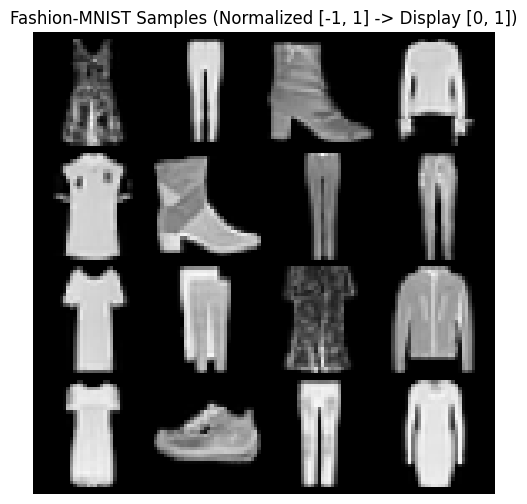

In [3]:
fashion_loader, fashion_ds = build_dataloader("../configs/datasets_config/fashion_mnist.yaml", split="train", batch_size=16)
imgs, labels = next(iter(fashion_loader))

print(f"Fashion-MNIST Batch shape: {imgs.shape} | Min: {imgs.min():.2f} | Max: {imgs.max():.2f}")

# Hiển thị ảnh mẫu
imgs_disp = denormalize(imgs, norm_range="[-1, 1]")
grid = torchvision.utils.make_grid(imgs_disp, nrow=4, padding=2)
plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("Fashion-MNIST Samples (Normalized [-1, 1] -> Display [0, 1])")
plt.axis("off")
plt.show()

## 4. Khởi tạo và Trực quan hóa CIFAR-10

In [ ]:
cifar_loader, cifar_ds = build_dataloader("../configs/datasets_config/cifar10.yaml", split="train", batch_size=16)
imgs_c, labels_c = next(iter(cifar_loader))

print(f"CIFAR-10 Batch shape: {imgs_c.shape} | Min: {imgs_c.min():.2f} | Max: {imgs_c.max():.2f}")

imgs_c_disp = denormalize(imgs_c, norm_range="[-1, 1]")
grid_c = torchvision.utils.make_grid(imgs_c_disp, nrow=4, padding=2)
plt.figure(figsize=(6, 6))
plt.imshow(grid_c.permute(1, 2, 0))
plt.title("CIFAR-10 Samples (32x32x3 RGB)")
plt.axis("off")
plt.show()

## 5. Khởi tạo và Trực quan hóa CelebA
CelebA gồm hơn 202.599 ảnh khuôn mặt được center-crop 140x140 và đưa về chuẩn 64x64 RGB, kèm nhãn điều kiện `Smiling` (0: Không cười, 1: Có cười).

In [ ]:
from datasets.preprocessing.celeba import find_celeba_img_dir

# Tự động tìm thư mục dữ liệu CelebA (hỗ trợ Colab / Kaggle / Local)
possible_celeba_dirs = [
    "/content/celeba",
    "/content/drive/MyDrive/BTL_DL_Data/celeba",
    "/kaggle/input/celeba-dataset",
    os.path.join(PROJECT_ROOT, "datasets/raw/celeba")
]

celeba_dir = None
for p in possible_celeba_dirs:
    if os.path.exists(p) and find_celeba_img_dir(p) is not None:
        celeba_dir = p
        break

config_path = os.path.join(PROJECT_ROOT, "configs/datasets_config/celeba.yaml")
with open(config_path, "r", encoding="utf-8") as f:
    celeba_cfg = yaml.safe_load(f)

if celeba_dir:
    print(f"Tìm thấy thư mục CelebA tại: {celeba_dir}")
    celeba_cfg["dataset"]["raw_dir"] = celeba_dir
    
    # Nạp 16 ảnh khuôn mặt và nhãn Smiling tương ứng
    celeb_loader, celeb_ds = build_dataloader(celeba_cfg, split="train", batch_size=16)
    imgs_celeb, labels_celeb = next(iter(celeb_loader))
    
    print(f"CelebA Batch shape: {imgs_celeb.shape} | Min: {imgs_celeb.min():.2f} | Max: {imgs_celeb.max():.2f}")
    print(f"Nhãn Smiling (1: Cười, 0: Không cười): {labels_celeb.tolist()}")
    
    # Giải chuẩn hóa [-1, 1] -> [0, 1] và hiển thị lưới ảnh
    imgs_celeb_disp = denormalize(imgs_celeb, norm_range="[-1, 1]")
    grid_celeb = torchvision.utils.make_grid(imgs_celeb_disp, nrow=4, padding=2)
    
    plt.figure(figsize=(7, 7))
    plt.imshow(grid_celeb.permute(1, 2, 0))
    plt.title("CelebA Face Samples (64x64 RGB, Normalized [-1, 1])")
    plt.axis("off")
    plt.show()
else:
    print("ℹ️ Chưa phát hiện ảnh CelebA trên máy này (thư mục datasets/raw/celeba trống).")
    print("👉 Khi chạy trên Google Colab:")
    print("   1. Hãy mount Google Drive: drive.mount('/content/drive')")
    print("   2. Giải nén vào /content/celeba để nạp ảnh siêu tốc!")
